<a href="https://colab.research.google.com/github/Navid-Meng/Rainy-Day-Classification-and-Weather-Pattern-Clustering-in-Phnom-Penh/blob/main/Rainy_Day_Classification_and_Weather_Pattern_Clustering_in_Phnom_Penh.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Rainy-Day Classification and Weather Pattern Clustering in Phnom Penh (2023–2025)
**Author:** Meng Navid  
**Course:** Machine Learning Fundamentals — Cambodia Academy of Digital Technology (CADT)

---
## Section 1: Data Acquisition, Validation & Target Creation (Steps 1–3)
* **Source:** Open-Meteo Historical Weather API for Phnom Penh (`11.5564°N, 104.9282°E`, `Asia/Phnom_Penh`).
* **Coverage:** 1 January 2023 to 31 December 2025 (`1,096` daily records, `0` missing values, `0` duplicate dates).
* **Target Definition (`is_rainy`):** `1` (Rainy) if `rain_sum > 0 mm`, and `0` (Dry) if `rain_sum == 0 mm`. Both `time` and `rain_sum` are excluded from model inputs to prevent target leakage.

In [1]:
import urllib.request
import pandas as pd
import numpy as np

# ==========================================
# STEP 1: Obtain Data & Inspect CSV Layout
# ==========================================
url = (
    "https://archive-api.open-meteo.com/v1/archive?"
    "latitude=11.5564&longitude=104.9282"
    "&start_date=2023-01-01&end_date=2025-12-31"
    "&daily=temperature_2m_max,temperature_2m_min,"
    "relative_humidity_2m_mean,wind_speed_10m_max,rain_sum"
    "&timezone=Asia%2FPhnom_Penh&format=csv"
)

csv_filename = "phnom_penh_weather_2023_2025.csv"
urllib.request.urlretrieve(url, csv_filename)

# Inspect the first 6 raw lines to check Open-Meteo metadata rows
print("--- Raw CSV Header Layout ---")
with open(csv_filename, "r", encoding="utf-8") as f:
    for i in range(6):
        print(f"Line {i}: {f.readline().strip()}")

# Dynamically find the line where the daily table starts ('time,')
header_row = 0
with open(csv_filename, "r", encoding="utf-8") as f:
    for i, line in enumerate(f):
        if line.startswith("time,"):
            header_row = i
            break

print(f"\nDetected table header at line: {header_row}")
df = pd.read_csv(csv_filename, skiprows=header_row)

# Standardize column names (strip units like '(°C)' if Open-Meteo includes them)
df.columns = [col.split(" ")[0].strip() for col in df.columns]

# ==========================================
# STEP 2: Dataset Inspection & Validation
# ==========================================
print("\n--- Dataset Shape & Columns ---")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")
print("Column names:", df.columns.tolist())

# Parse date and check coverage + duplicates
df["time"] = pd.to_datetime(df["time"])
print(f"\nDate range: {df['time'].min().date()} to {df['time'].max().date()}")
print(f"Duplicate dates count: {df['time'].duplicated().sum()}")

print("\n--- Missing Values per Column ---")
print(df.isnull().sum())

# ==========================================
# STEP 3: Target Creation & Summary Stats
# ==========================================
# Drop rows with missing values if any exist, after logging them
df_clean = df.dropna().copy()

# Create binary target: 1 if rain_sum > 0 mm, 0 if rain_sum == 0 mm
df_clean["is_rainy"] = (df_clean["rain_sum"] > 0).astype(int)

print("\n--- Summary Statistics ---")
print(df_clean.describe().round(2))

print("\n--- Overall Class Balance (2023-2025) ---")
class_counts = df_clean["is_rainy"].value_counts().rename({0: "Dry (0)", 1: "Rainy (1)"})
class_props = (df_clean["is_rainy"].value_counts(normalize=True) * 100).round(2).rename({0: "Dry %", 1: "Rainy %"})
print(pd.DataFrame({"Count": class_counts, "Percentage": class_props.values}))

print("\n--- Class Balance by Year (Checking 2023-2024 Train vs 2025 Test) ---")
df_clean["year"] = df_clean["time"].dt.year
print(pd.crosstab(df_clean["year"], df_clean["is_rainy"], margins=True))

--- Raw CSV Header Layout ---
Line 0: latitude,longitude,elevation,utc_offset_seconds,timezone,timezone_abbreviation
Line 1: 11.564148,104.94643,14.0,25200,Asia/Phnom_Penh,GMT+7
Line 2: 
Line 3: time,temperature_2m_max (°C),temperature_2m_min (°C),relative_humidity_2m_mean (%),wind_speed_10m_max (km/h),rain_sum (mm)
Line 4: 2023-01-01,26.9,20.9,68,17.7,0.00
Line 5: 2023-01-02,28.3,22.6,71,14.7,0.60

Detected table header at line: 3

--- Dataset Shape & Columns ---
Rows: 1096, Columns: 6
Column names: ['time', 'temperature_2m_max', 'temperature_2m_min', 'relative_humidity_2m_mean', 'wind_speed_10m_max', 'rain_sum']

Date range: 2023-01-01 to 2025-12-31
Duplicate dates count: 0

--- Missing Values per Column ---
time                         0
temperature_2m_max           0
temperature_2m_min           0
relative_humidity_2m_mean    0
wind_speed_10m_max           0
rain_sum                     0
dtype: int64

--- Summary Statistics ---
                      time  temperature_2m_max  tempe

## Section 2: Exploratory Data Analysis, Supervised Classification & K-Means Clustering (Steps 4–8)
1. **Exploratory Data Analysis (EDA):** Visualize overall/yearly class balance and the distributions of the four input features (`temperature_2m_max`, `temperature_2m_min`, `relative_humidity_2m_mean`, `wind_speed_10m_max`).
2. **Supervised Learning (Chronological Split):** Train on `2023–2024` (`731` days) and evaluate on unseen `2025` (`365` days) comparing **Logistic Regression** (`StandardScaler`, `max_iter=1000`) and **Decision Tree Classifier** (`max_depth=4`, `random_state=42`).
3. **Unsupervised Learning (K-Means Clustering):** Standardize the four weather features across all `1,096` days (without `is_rainy` labels) and evaluate $K \in \{2, 3, 4\}$ using Silhouette Scores and unscaled cluster centroids.

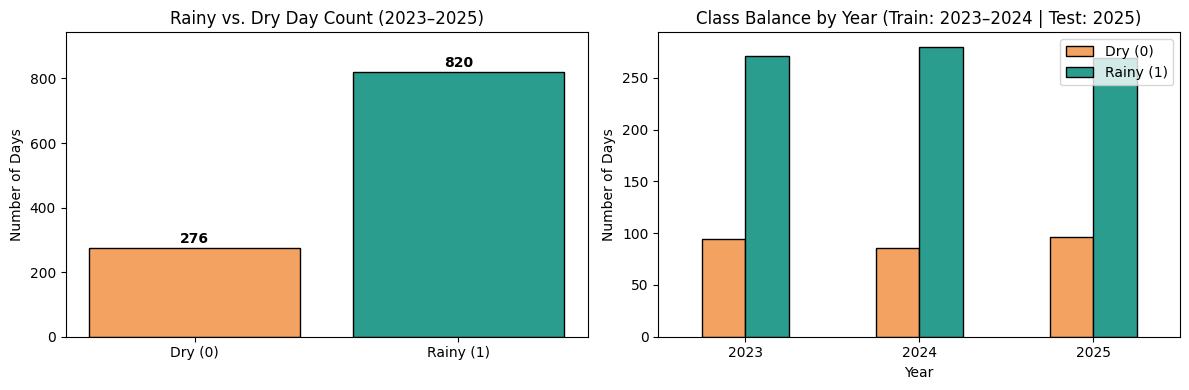

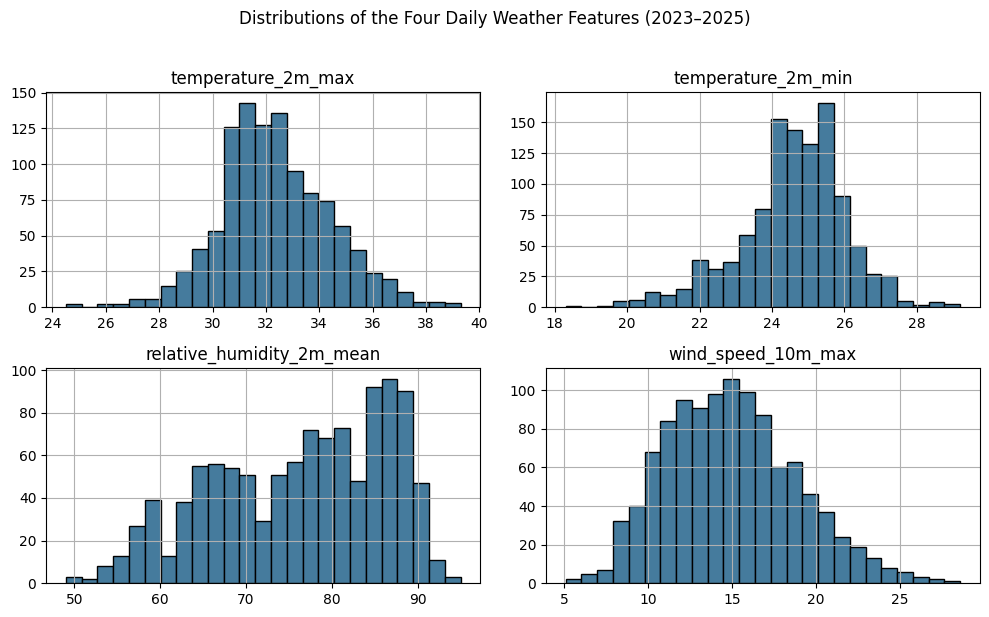

Training set (2023–2024): 731 days
Testing set (2025):       365 days

=== SUPERVISED CLASSIFICATION RESULTS (2025 TEST SET) ===
             Classifier  Accuracy  Precision (Rainy)  Recall (Rainy)  F1 (Rainy)  TN (Dry->Dry)  FP (Dry->Rainy)  FN (Rainy->Dry)  TP (Rainy->Rainy)
    Logistic Regression    0.9123             0.9405          0.9405      0.9405             80               16               16                253
Decision Tree (depth=4)    0.9014             0.9059          0.9665      0.9353             69               27                9                260


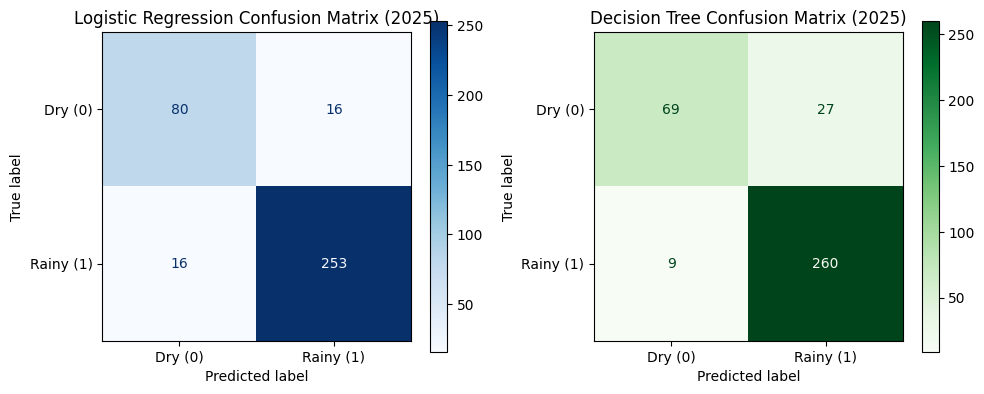


=== K-MEANS CLUSTERING RESULTS (2023–2025) ===

--- Cluster Averages for K = 2 (Silhouette Score: 0.2609) ---
            temperature_2m_max  temperature_2m_min  relative_humidity_2m_mean  \
cluster_k2                                                                      
0                        31.19               24.09                      80.53   
1                        34.31               25.42                      69.32   

            wind_speed_10m_max  Day Count  Rainy Days (%)  
cluster_k2                                                 
0                        14.40        685            77.4  
1                        15.91        411            70.6  

--- Cluster Averages for K = 3 (Silhouette Score: 0.3241) ---
            temperature_2m_max  temperature_2m_min  relative_humidity_2m_mean  \
cluster_k3                                                                      
0                        34.76               25.73                      69.70   
1                 

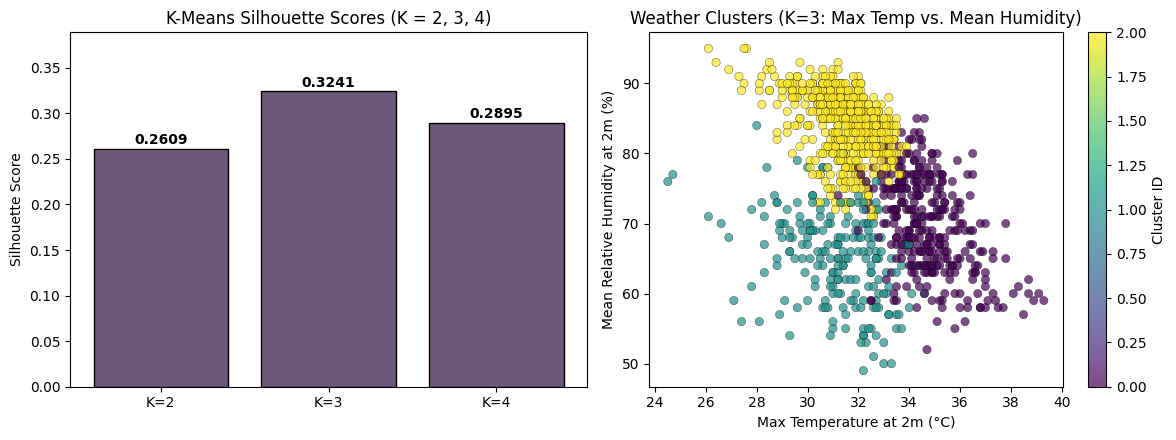

In [ ]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    silhouette_score,
)
from sklearn.cluster import KMeans

# Define the 4 input features (excluding 'time' and 'rain_sum' to prevent target leakage)
features = [
    "temperature_2m_max",
    "temperature_2m_min",
    "relative_humidity_2m_mean",
    "wind_speed_10m_max",
]
target = "is_rainy"

# ==========================================
# STEP 4: Exploratory Data Analysis (EDA)
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# 4a. Overall Class Balance Bar Chart
class_counts = df_clean[target].value_counts().sort_index()
axes[0].bar(
    ["Dry (0)", "Rainy (1)"],
    class_counts.values,
    color=["#f4a261", "#2a9d8f"],
    edgecolor="black",
)
axes[0].set_title("Rainy vs. Dry Day Count (2023–2025)")
axes[0].set_ylabel("Number of Days")
for i, v in enumerate(class_counts.values):
    axes[0].text(i, v + 15, str(v), ha="center", fontweight="bold")
axes[0].set_ylim(0, max(class_counts.values) * 1.15)

# 4b. Class Balance by Year
yearly_counts = pd.crosstab(df_clean["year"], df_clean[target])
yearly_counts.columns = ["Dry (0)", "Rainy (1)"]
yearly_counts.plot(
    kind="bar",
    ax=axes[1],
    color=["#f4a261", "#2a9d8f"],
    edgecolor="black",
    rot=0,
)
axes[1].set_title("Class Balance by Year (Train: 2023–2024 | Test: 2025)")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Number of Days")
plt.tight_layout()
plt.show()

# 4c. Feature Distributions
df_clean[features].hist(bins=25, figsize=(10, 6), edgecolor="black", color="#457b9d")
plt.suptitle("Distributions of the Four Daily Weather Features (2023–2025)", y=1.02)
plt.tight_layout()
plt.show()

# ==========================================
# STEP 5: Train Supervised Classifiers
# ==========================================
# Chronological split: Train on 2023-2024, Test on 2025
train_mask = df_clean["year"].isin([2023, 2024])
test_mask = df_clean["year"] == 2025

X_train = df_clean.loc[train_mask, features]
y_train = df_clean.loc[train_mask, target]
X_test = df_clean.loc[test_mask, features]
y_test = df_clean.loc[test_mask, target]

print(f"Training set (2023–2024): {X_train.shape[0]} days")
print(f"Testing set (2025):       {X_test.shape[0]} days\n")

# 5a. Logistic Regression (scale features using training statistics only)
scaler_clf = StandardScaler()
X_train_scaled = scaler_clf.fit_transform(X_train)
X_test_scaled = scaler_clf.transform(X_test)

log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)
y_pred_lr = log_reg.predict(X_test_scaled)

# 5b. Decision Tree Classifier (max_depth=4, random_state=42)
dt_clf = DecisionTreeClassifier(max_depth=4, random_state=42)
dt_clf.fit(X_train, y_train)
y_pred_dt = dt_clf.predict(X_test)

# ==========================================
# STEP 6: Evaluate & Compare Classifiers
# ==========================================
def get_metrics(y_true, y_pred, model_name):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    return {
        "Classifier": model_name,
        "Accuracy": round(accuracy_score(y_true, y_pred), 4),
        "Precision (Rainy)": round(precision_score(y_true, y_pred, pos_label=1), 4),
        "Recall (Rainy)": round(recall_score(y_true, y_pred, pos_label=1), 4),
        "F1 (Rainy)": round(f1_score(y_true, y_pred, pos_label=1), 4),
        "TN (Dry->Dry)": tn,
        "FP (Dry->Rainy)": fp,
        "FN (Rainy->Dry)": fn,
        "TP (Rainy->Rainy)": tp,
    }

results_df = pd.DataFrame([
    get_metrics(y_test, y_pred_lr, "Logistic Regression"),
    get_metrics(y_test, y_pred_dt, "Decision Tree (depth=4)"),
])

print("=== SUPERVISED CLASSIFICATION RESULTS (2025 TEST SET) ===")
print(results_df.to_string(index=False))

# Plot Confusion Matrices side by side
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_lr, display_labels=["Dry (0)", "Rainy (1)"], cmap="Blues", ax=axes[0]
)
axes[0].set_title("Logistic Regression Confusion Matrix (2025)")

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_dt, display_labels=["Dry (0)", "Rainy (1)"], cmap="Greens", ax=axes[1]
)
axes[1].set_title("Decision Tree Confusion Matrix (2025)")
plt.tight_layout()
plt.show()

# ==========================================
# STEP 7 & 8: K-Means Clustering (K = 2, 3, 4)
# ==========================================
# Standardize all 4 weather features across the full dataset (no labels given)
scaler_km = StandardScaler()
X_all_scaled = scaler_km.fit_transform(df_clean[features])

k_values = [2, 3, 4]
silhouette_results = []
best_k = None
best_score = -1

print("\n=== K-MEANS CLUSTERING RESULTS (2023–2025) ===")
for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = km.fit_predict(X_all_scaled)
    score = silhouette_score(X_all_scaled, cluster_labels)
    silhouette_results.append({"K": k, "Silhouette Score": round(score, 4)})
    df_clean[f"cluster_k{k}"] = cluster_labels

    if score > best_score:
        best_score = score
        best_k = k

    print(f"\n--- Cluster Averages for K = {k} (Silhouette Score: {score:.4f}) ---")
    profile = df_clean.groupby(f"cluster_k{k}")[features].mean().round(2)
    profile["Day Count"] = df_clean[f"cluster_k{k}"].value_counts()
    # Post-hoc check of rainy proportion (not used during clustering)
    profile["Rainy Days (%)"] = (df_clean.groupby(f"cluster_k{k}")[target].mean() * 100).round(1)
    print(profile)

sil_df = pd.DataFrame(silhouette_results)
print("\n--- Silhouette Score Summary ---")
print(sil_df.to_string(index=False))

# Plot Silhouette Scores and 2D Cluster Scatter Plot
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].bar(
    [f"K={k}" for k in sil_df["K"]],
    sil_df["Silhouette Score"],
    color="#6d597a",
    edgecolor="black",
)
axes[0].set_title("K-Means Silhouette Scores (K = 2, 3, 4)")
axes[0].set_ylabel("Silhouette Score")
for i, v in enumerate(sil_df["Silhouette Score"]):
    axes[0].text(i, v + 0.005, f"{v:.4f}", ha="center", fontweight="bold")
axes[0].set_ylim(0, max(sil_df["Silhouette Score"]) * 1.2)

scatter = axes[1].scatter(
    df_clean["temperature_2m_max"],
    df_clean["relative_humidity_2m_mean"],
    c=df_clean[f"cluster_k{best_k}"],
    cmap="viridis",
    alpha=0.7,
    edgecolors="k",
    linewidth=0.3,
)
axes[1].set_title(f"Weather Clusters (K={best_k}: Max Temp vs. Mean Humidity)")
axes[1].set_xlabel("Max Temperature at 2m (°C)")
axes[1].set_ylabel("Mean Relative Humidity at 2m (%)")
plt.colorbar(scatter, ax=axes[1], label="Cluster ID")
plt.tight_layout()
plt.show()

## Section 3: Domain Critique — Rainfall Threshold Sensitivity Analysis
Because Open-Meteo ERA5 reanalysis represents area-averaged grid estimates, trace moisture (`0.1–0.9 mm` on 209 days) inflates the baseline `> 0.0 mm` rainy-day count to `74.8%` (`~273 days/year`). Below, we evaluate standard meteorological thresholds (`>= 1.0 mm`, `>= 2.0 mm`, and `>= 5.0 mm`) to compare reanalysis drizzle against real-world Phnom Penh rainfall patterns.

In [ ]:
print("=== HOW MANY DAYS ARE ACTUALLY RAINY AT DIFFERENT THRESHOLDS? ===")
for threshold in [0.0, 1.0, 2.0, 5.0]:
    if threshold == 0.0:
        rainy_days = (df_clean["rain_sum"] > 0).sum()
        rule = "> 0.0 mm (Any trace drop)"
    else:
        rainy_days = (df_clean["rain_sum"] >= threshold).sum()
        rule = f">= {threshold:.1f} mm (Real rain)"

    pct = (rainy_days / len(df_clean)) * 100
    avg_per_year = rainy_days / 3
    print(f"Rule {rule:26s} -> {rainy_days:3d} days ({pct:5.1f}%) | ~{avg_per_year:.0f} rainy days/year")

=== HOW MANY DAYS ARE ACTUALLY RAINY AT DIFFERENT THRESHOLDS? ===
Rule > 0.0 mm (Any trace drop)  -> 820 days ( 74.8%) | ~273 rainy days/year
Rule >= 1.0 mm (Real rain)      -> 611 days ( 55.7%) | ~204 rainy days/year
Rule >= 2.0 mm (Real rain)      -> 538 days ( 49.1%) | ~179 rainy days/year
Rule >= 5.0 mm (Real rain)      -> 397 days ( 36.2%) | ~132 rainy days/year
